# v37 lab — run平均ランカーの深堀り(目的関数・モデル族の比較, 1回=1変更)
基準: cons 7.1055 / **f_runmean(TCN+listwise KL)= 6.7485** / oracle(1本) 4.8783。
参考: blend 6.8711 / gate 6.5288。**目標: 回収15%→25-30%(OOF 6.5台)= 純PF単独でgate級**。

| RUN | 種別 | 変更点 |
|---|---|---|
| base_kl | 再現 | v34 f_runmean と同じ listwise KL(このlabのコードでの錨) |
| g_e2e | **目的関数** | softmax重み→加重平均→**pooled MSE を直接最適化**(代理目的の排除) |
| h_row | **表現力** | **行レベル重み wᵢ(t)**(=乗り移り解禁)+TV平滑化。e2e損失 |
| i_pair | 目的関数 | RankNet: ペア比較 σ(sᵢ−sⱼ)、|Δez|重み付きBCE |
| j_img | モデル族 | 候補をオフセット順に並べ **2D CNN**(候補×時間の画像として畳み込み) |
| k_attn | モデル族 | base_kl + 候補間 set-attention(27候補での再挑戦) |

プロトコル: 固定fold(v34/ranker_folds.json 共有)/ スコア型は softmax β{0.5,1,1.5,2}+top-n{2,4,8} /
e2e型は自前集約をそのまま評価 / foldチェックポイント(v37_est|q_{RUN}_f*.npz)/ 結果は ranker_v37_results.json。


In [7]:
# ===== ロード + RM候補(27本, オフセット順ソート) =====
import json, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = "Meiryo"; matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
V28_ART = PROJECT / "v28" / "artifacts_v28"
V284_PQ = PROJECT / "v28" / "artifacts_v28_4" / "data" / "train.parquet"
V34_ART = PROJECT / "v34" / "artifacts_v34"
ART = PROJECT / "v37" / "artifacts_v37"; ART.mkdir(parents=True, exist_ok=True)

tbl = pq.read_table(V28_ART / "data" / "train.parquet",
                    columns=["well", "target", "last_known_tvt", "pf_nbr_has",
                             "pf_nbr_nrefs", "pf_nbr_nndist", "md_since"])
g = tbl.column("well").to_pandas().to_numpy()
lk = tbl.column("last_known_tvt").to_numpy(zero_copy_only=False).astype(np.float64)
tvt_true = lk + tbl.column("target").to_numpy(zero_copy_only=False).astype(np.float64)
has = tbl.column("pf_nbr_has").to_numpy(zero_copy_only=False).astype(np.float64)
nrefs_c = tbl.column("pf_nbr_nrefs").to_numpy(zero_copy_only=False).astype(np.float64)
nnd_c = tbl.column("pf_nbr_nndist").to_numpy(zero_copy_only=False).astype(np.float64)
mds_c = tbl.column("md_since").to_numpy(zero_copy_only=False).astype(np.float64)
wid = list(pd.unique(g)); rows_of = {w: np.where(g == w)[0] for w in wid}
def rmse(e):
    e = e[np.isfinite(e)]
    return float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
FOLD = {k: int(v) for k, v in json.loads((V34_ART / "ranker_folds.json").read_text()).items()}

PF_BANKS = ["pf1", "pf2", "pf3"]; R_BANKS = ["rp1", "rp2", "rp3"]
BANKS = PF_BANKS + R_BANKS
SRCS = ("tw", "self", "nbr"); FLTS = (("sm", "ps"), ("fw", "pfw"))
DUMPS = {b: np.load(V34_ART / f"seed_dump_pf{b[-1]}.npz") for b in PF_BANKS}
KEYS = {b: set(DUMPS[b].files) for b in PF_BANKS}
RCOL = {("rp1", "tw"): "pf_ancc_1", ("rp2", "tw"): "pf_ancc_2", ("rp3", "tw"): "pf_ancc_3",
        ("rp1", "self"): "pf_self_1", ("rp2", "self"): "pf_self_2", ("rp3", "self"): "pf_self_3",
        ("rp1", "nbr"): "pf_nbr_1", ("rp2", "nbr"): "pf_nbr_2", ("rp3", "nbr"): "pf_nbr_3"}
RSTD = {"rp1": "pf_ancc_std_1", "rp2": "pf_ancc_std_2", "rp3": "pf_ancc_std_3"}
t4 = pq.read_table(V284_PQ, columns=["well"] + sorted(set(RCOL.values()) | set(RSTD.values())))
assert (t4.column("well").to_pandas().to_numpy() == g).all()
C4 = {c: t4.column(c).to_numpy(zero_copy_only=False).astype(np.float64) for c in t4.schema.names if c != "well"}
del t4
_rg = np.load(V34_ART / "rgrid_cache.npz")
RGRID = {}
for key in _rg.files:
    w, b, kind = key.split("|")
    RGRID.setdefault((w, b), {})[kind] = _rg[key]

t0 = time.time(); RM = {}
for w in wid:
    r = rows_of[w]
    nbr_ok = np.nanmean(has[r]) > 0.5
    trs, meta = [], []
    Tmin = len(r)
    for b in PF_BANKS:
        z = DUMPS[b]
        for src in SRCS:
            if src == "nbr" and not nbr_ok: continue
            if f"{w}|ps_{src}" not in KEYS[b]: continue
            ww_ = z[f"{w}|ww_{src}"]
            for flt, pref in FLTS:
                ps = z[f"{w}|{pref}_{src}"]
                Tmin = min(Tmin, ps.shape[1])
                tr_ = (ww_[:, None] * ps.astype(np.float64)).sum(0)
                dse = float(np.nanstd(np.nanmedian(ps.astype(np.float64) - tr_[None, :ps.shape[1]], axis=1)))
                went = float(-(ww_ * np.log(np.maximum(ww_, 1e-12))).sum())
                trs.append(tr_); meta.append((b, src, flt, dse, went, float(ww_.max())))
    for b in R_BANKS:
        if (w, b) not in RGRID: continue
        dse = float(np.nanmedian(C4[RSTD[b]][r]))
        for src in SRCS:
            if src == "nbr" and not nbr_ok: continue
            v = C4[RCOL[(b, src)]][r]
            if np.isfinite(v).sum() < max(10, 0.3 * len(r)): continue
            trs.append(v.copy()); meta.append((b, src, "sm", dse, 0.0, 0.0))
    if len(trs) < 4 or Tmin < 5: continue
    TR = np.stack([t_[:Tmin] for t_ in trs], 0)
    err = np.nanmedian(np.abs(TR - tvt_true[r[:Tmin]][None, :]), axis=1)
    ok = np.isfinite(err)
    if ok.sum() < 4: continue
    TR = TR[ok]; err = err[ok]; meta = [m for m, o in zip(meta, ok) if o]
    cons = np.nanmedian(TR, axis=0)
    TR = np.where(np.isfinite(TR), TR, cons[None, :])   # ★散発NaNはconsで埋める(0埋めはTVT=0の壊滅候補になる)
    d_off = np.nanmedian(TR - cons[None, :], axis=1)
    order = np.argsort(d_off)                       # ★オフセット順ソート(j_imgの候補軸局所性のため。他は不変)
    TR = TR[order]; err = err[order]; meta = [meta[i] for i in order]
    d_off = d_off[order]
    # ---- 特徴A: モード文脈(v34ゲートでAUC0.92を出した信号を候補ごとに付与)----
    n = len(TR)
    lab_m = np.zeros(n, int); cur = 0
    for i in range(1, n):
        if d_off[i] - d_off[i - 1] > 8.0: cur += 1
        lab_m[i] = cur
    n_modes = cur + 1
    centers = np.array([np.median(d_off[lab_m == m]) for m in range(n_modes)])
    sizes = np.array([(lab_m == m).sum() for m in range(n_modes)], float)
    top_m = int(np.argmax(sizes))
    ext_of = np.array([np.mean([meta[i][1] in ("self", "nbr") for i in range(n) if lab_m[i] == m])
                       for m in range(n_modes)])
    mc = np.stack([sizes[lab_m] / n,                          # 所属モードの質量
                   ext_of[lab_m],                             # 所属モードのext(self/nbr)支持率
                   (lab_m == top_m).astype(float)], 1)        # topモードか
    gap2 = float(abs(np.diff(np.sort(centers)[-2:])[0])) if n_modes >= 2 else 0.0
    stay_share = float(np.mean(np.abs(d_off) < 4.0))
    # ---- 特徴B: 井戸コンテキスト ----
    r0_ = rows_of[w]
    md_len = float(np.nanmax(mds_c[r0_])) if np.isfinite(mds_c[r0_]).any() else 0.0
    disp = float(np.nanmedian(np.nanpercentile(TR, 90, axis=0) - np.nanpercentile(TR, 10, axis=0)))
    wellstat = np.array([n_modes / 5.0, min(gap2, 60.0) / 30.0, stay_share, min(disp, 40.0) / 20.0,
                         min(float(np.nanmedian(nnd_c[r0_])), 3000.0) / 1000.0,
                         float(np.nanmedian(nrefs_c[r0_])) / 3.0,
                         md_len / 5000.0, len(r0_) / 2000.0], np.float32)
    RM[w] = dict(TR=TR.astype(np.float32), T=Tmin, err=err.astype(np.float32), meta=meta,
                 mc=mc.astype(np.float32), wellstat=wellstat,
                 cons=cons.astype(np.float32),
                 p10=np.nanpercentile(TR, 10, axis=0).astype(np.float32),
                 p90=np.nanpercentile(TR, 90, axis=0).astype(np.float32))
TRUE = {w: tvt_true[rows_of[w][:RM[w]["T"]]] for w in RM}
cons_ov = rmse(np.concatenate([RM[w]["cons"] - TRUE[w] for w in RM]))
or1_ov = rmse(np.concatenate([RM[w]["TR"][int(np.argmin(RM[w]["err"]))] - TRUE[w] for w in RM]))
print(f"RM {len(RM)}井戸 / 平均候補 {np.mean([len(RM[w]['TR']) for w in RM]):.1f}本 ({time.time()-t0:.0f}s)")
print(f"cons {cons_ov:.4f} / oracle(1本) {or1_ov:.4f} / 参考: f_runmean(KL) 6.7485")


RM 773井戸 / 平均候補 24.8本 (368s)
cons 7.1055 / oracle(1本) 4.8783 / 参考: f_runmean(KL) 6.7485


In [8]:
# ===== チャネル前計算(GPU常駐)+ 全解像度軌跡/真値テンソル =====
import torch, torch.nn as nn, torch.nn.functional as F
DEV = "cuda" if torch.cuda.is_available() else "cpu"
STRIDE, TAU = 4, 0.5
torch.manual_seed(0)
B_ID = {b: i for i, b in enumerate(BANKS)}; S_ID = {"tw": 0, "self": 1, "nbr": 2}
META_DIM = len(BANKS) + 3 + 1 + 3 + 3 + 8   # 従来13 + モード文脈3(A) + 井戸コンテキスト8(B)
N_CH = 8                                    # 波形7 + 合意密度1(C)

def _grids_of(w, b):
    if b in PF_BANKS:
        z = DUMPS[b]
        out = dict(meta=z[f"{w}|meta"], gr=z[f"{w}|gr"], md=z[f"{w}|md"], zz=z[f"{w}|z"],
                   ir=float(z[f"{w}|ir"]), gg_tw=z[f"{w}|gg_tw"], gg_self=z[f"{w}|gg_self"])
        if f"{w}|gg_nbr" in KEYS[b]: out["gg_nbr"] = z[f"{w}|gg_nbr"]
        return out
    d = RGRID.get((w, b))
    if d is None: return None
    out = dict(meta=d["meta"], gr=d["gr"], md=d["md"], zz=d["z"], ir=float(d["ir"][0]),
               gg_tw=d["gg_tw"], gg_self=d["gg_self"])
    if "gg_nbr" in d: out["gg_nbr"] = d["gg_nbr"]
    return out

def build_ch(w):
    d = RM[w]; T = d["T"]
    TR = d["TR"][:, ::STRIDE].astype(np.float32)
    cons = d["cons"][::STRIDE]; p10 = d["p10"][::STRIDE]; p90 = d["p90"][::STRIDE]
    n = len(TR)
    g0 = _grids_of(w, "pf1")
    md_ = g0["md"].astype(np.float32)[:T][::STRIDE]; zz = g0["zz"].astype(np.float32)[:T][::STRIDE]
    ir0 = g0["ir"]
    off = np.clip((TR - cons[None, :]) / 10.0, -6, 6)
    env = np.clip((TR - p10[None, :]) / (p90 - p10 + 1e-3)[None, :] - 0.5, -3, 3)
    dmd = np.maximum(np.diff(md_), 1.0)
    dip = np.zeros_like(TR)
    dip[:, 1:] = np.clip(np.nan_to_num((np.diff(TR + zz[None, :], axis=1) / dmd[None, :] - ir0) * 100.0), -4, 4)
    RES = {k: np.zeros_like(TR) for k in ("tw", "self", "nbr")}
    for i, (b, src, flt, dse, went, wmax) in enumerate(d["meta"]):
        gb = _grids_of(w, b)
        if gb is None: continue
        gmin, gst, gs = gb["meta"]; gr = gb["gr"].astype(np.float32)[:T][::STRIDE]
        for nmk in ("tw", "self", "nbr"):
            gg = gb.get(f"gg_{nmk}")
            if gg is None: continue
            gg = gg.astype(np.float32); G = len(gg)
            ii = np.clip(np.nan_to_num((TR[i] - gmin) / gst), 0.0, G - 1.000001)
            i0 = ii.astype(int); t = ii - i0
            eg = gg[i0] * (1 - t) + gg[np.minimum(i0 + 1, G - 1)] * t
            RES[nmk][i] = np.clip(np.nan_to_num((gr - eg) / max(float(gs), 1e-3)), -4, 4)
    grz = g0["gr"].astype(np.float32)[:T][::STRIDE]
    grz = np.clip((grz - np.nanmedian(grz)) / (np.nanstd(grz) + 1e-3), -4, 4)
    grz = np.nan_to_num(np.broadcast_to(grz, (n, len(grz))))
    # ---- 特徴C: 行レベル合意密度(行tで±3ft以内にいる他候補の割合=多数派バンドル度)----
    dens = (np.abs(TR[:, None, :] - TR[None, :, :]) < 3.0).mean(axis=1).astype(np.float32)
    X = np.stack([np.nan_to_num(off), np.nan_to_num(env), RES["tw"], RES["self"], RES["nbr"],
                  dip, grz, dens], 1)
    M = np.zeros((n, META_DIM), np.float32)
    base13 = len(BANKS) + 3 + 1 + 3
    for i, (b, src, flt, dse, went, wmax) in enumerate(d["meta"]):
        M[i, B_ID[b]] = 1; M[i, len(BANKS) + S_ID[src]] = 1
        M[i, len(BANKS) + 3] = float(flt == "sm")
        M[i, len(BANKS) + 4] = min(dse, 25.0) / 5.0
        M[i, len(BANKS) + 5] = went / 3.5; M[i, len(BANKS) + 6] = wmax
    M[:, base13:base13 + 3] = d["mc"]                       # A: モード文脈
    M[:, base13 + 3:base13 + 11] = d["wellstat"][None, :]   # B: 井戸コンテキスト
    return np.ascontiguousarray(X).astype(np.float16), M

print("前計算 ...", flush=True); t0 = time.time()
CH = {}; MB = {}; PSTAR = {}; EZ = {}; TRF = {}; TRUT = {}
for w in RM:
    xw, mw = build_ch(w)
    CH[w] = torch.from_numpy(xw).to(DEV); MB[w] = torch.from_numpy(mw).to(DEV)
    e = RM[w]["err"].astype(np.float64)
    ez = ((e - e.mean()) / (e.std() + 1e-9)).astype(np.float32)
    EZ[w] = ez
    PSTAR[w] = F.softmax(torch.from_numpy(-ez / TAU).to(DEV), 0)
    TRF[w] = torch.from_numpy(np.nan_to_num(RM[w]["TR"]).astype(np.float32)).to(DEV)
    TRUT[w] = torch.from_numpy(np.nan_to_num(TRUE[w]).astype(np.float32)).to(DEV)
print(f"  done {time.time()-t0:.0f}s")


前計算 ...
  done 10s


In [15]:
# ===== プリセット =====
PRESETS = {
    "base_kl": dict(kind="kl"),
    "g_e2e":   dict(kind="e2e"),
    "g2_hyb":  dict(kind="hyb", lam_kl=0.3),   # e2e + 0.3·KL(順位錨でe2eの分散を抑える折衷)
    "h_row":   dict(kind="row", tv=1.0),
    "i_pair":  dict(kind="pair", npairs=64),
    "j_img":   dict(kind="img"),
    "k_attn":  dict(kind="attn"),
    "m_imm":   dict(kind="imm"),   # 学習なし: IMM/HMM構造の行レベル重み(リサーチ提言。h_rowの理論的に正しい形)
}
RUN = "k_attn"
CFG = PRESETS[RUN]
EPOCHS, LR = 20, 3e-4
print("RUN =", RUN, CFG)


RUN = k_attn {'kind': 'attn'}


In [16]:
# ===== モデル定義 + 学習(foldチェックポイント付き) =====
class ChanLN(nn.Module):
    def __init__(self, c):
        super().__init__(); self.ln = nn.LayerNorm(c)
    def forward(self, x): return self.ln(x.transpose(1, 2)).transpose(1, 2)

class Enc(nn.Module):
    def __init__(self, cin=N_CH, ch=32):
        super().__init__()
        self.inp = nn.Conv1d(cin, ch, 1)
        self.blocks = nn.ModuleList()
        for dil in (1, 2, 4, 8):
            self.blocks.append(nn.ModuleList([
                nn.Conv1d(ch, ch, 5, padding=2 * dil, dilation=dil), ChanLN(ch), nn.Conv1d(ch, ch, 1)]))
    def forward(self, x):
        h = self.inp(x)
        for cv, ln, pw in self.blocks:
            h = h + pw(F.gelu(ln(cv(h))))
        return h                                   # (n,ch,Td)

class Net(nn.Module):
    """kind: kl/e2e/pair/attn = スコア1個, row = スコア+行logit"""
    def __init__(self, kind, ch=32, dmeta=META_DIM):
        super().__init__()
        self.kind = kind
        self.enc = Enc(N_CH, ch)
        self.emb = nn.Linear(2 * ch, 64)
        self.mp = nn.Sequential(nn.Linear(dmeta, 64), nn.GELU(), nn.Linear(64, 64))
        self.head = nn.Sequential(nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 1))
        if kind == "row":
            self.rowh = nn.Conv1d(ch, 1, 1)
            self.gamma = nn.Parameter(torch.tensor(0.1))
        if kind == "attn":
            self.q = nn.Linear(64, 64); self.kk = nn.Linear(64, 64); self.v = nn.Linear(64, 64)
            self.aln = nn.LayerNorm(64)
    def forward(self, x, meta):
        h = self.enc(x)
        e = self.emb(torch.cat([h.mean(-1), h.amax(-1)], -1)) + self.mp(meta)
        if self.kind == "attn":
            a = F.scaled_dot_product_attention(self.q(e)[None], self.kk(e)[None], self.v(e)[None])[0]
            e = self.aln(e + a)
        s = self.head(e).squeeze(-1)
        if self.kind == "row":
            return s, self.rowh(h).squeeze(1)      # (n,), (n,Td)
        return s, None

class ImgNet(nn.Module):
    """候補×時間を2D画像として畳み込み(候補軸はオフセット順ソート済=局所性あり)"""
    def __init__(self, cin=N_CH, ch=32, dmeta=META_DIM):
        super().__init__()
        self.c1 = nn.Conv2d(cin, ch, (3, 5), padding=(1, 2))
        self.c2 = nn.Conv2d(ch, ch, (3, 5), padding=(1, 4), dilation=(1, 2))
        self.c3 = nn.Conv2d(ch, ch, (3, 5), padding=(1, 8), dilation=(1, 4))
        self.emb = nn.Linear(2 * ch, 64)
        self.mp = nn.Sequential(nn.Linear(dmeta, 64), nn.GELU(), nn.Linear(64, 64))
        self.head = nn.Sequential(nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 1))
    def forward(self, x, meta):
        z = x.transpose(0, 1)[None]                # (1,7,n,Td)
        z = F.gelu(self.c1(z)); z = z + F.gelu(self.c2(z)); z = z + F.gelu(self.c3(z))
        z = z[0].permute(1, 0, 2)                  # (n,ch,Td)
        e = self.emb(torch.cat([z.mean(-1), z.amax(-1)], -1)) + self.mp(meta)
        return self.head(e).squeeze(-1), None

def make_est_row(s, L, w, gamma):
    """行レベル重み: logits = s_i + γ·L_i(t) → 行ごとsoftmax → 全解像度に展開して加重平均"""
    T = RM[w]["T"]
    logits = s[:, None] + gamma * L                # (n,Td)
    idx = torch.arange(T, device=s.device) // STRIDE
    idx = idx.clamp(max=L.shape[1] - 1)
    wfull = F.softmax(logits, 0)[:, idx]           # (n,T)
    return (wfull * TRF[w]).sum(0), F.softmax(logits, 0)

def loss_of(w, mdl):
    x = CH[w].float(); meta = MB[w]
    s, L = mdl(x, meta)
    if CFG["kind"] in ("kl", "attn", "img"):
        return -(PSTAR[w] * F.log_softmax(s, 0)).sum(), None
    if CFG["kind"] == "e2e":
        wgt = F.softmax(s, 0)
        est = (wgt[:, None] * TRF[w]).sum(0)
        return (((est - TRUT[w]) / 10.0) ** 2).mean(), None
    if CFG["kind"] == "hyb":
        wgt = F.softmax(s, 0)
        est = (wgt[:, None] * TRF[w]).sum(0)
        return ((((est - TRUT[w]) / 10.0) ** 2).mean()
                + CFG["lam_kl"] * (-(PSTAR[w] * F.log_softmax(s, 0)).sum())), None
    if CFG["kind"] == "row":
        est, wsm = make_est_row(s, L, w, mdl.gamma)
        tv = (wsm[:, 1:] - wsm[:, :-1]).abs().mean()
        return (((est - TRUT[w]) / 10.0) ** 2).mean() + CFG["tv"] * tv, None
    if CFG["kind"] == "pair":
        n = len(s); rng_ = torch.randint(0, n, (2, CFG["npairs"]), device=s.device)
        a, b = rng_[0], rng_[1]
        ez = torch.from_numpy(EZ[w]).to(s.device)
        y = (ez[a] < ez[b]).float()
        wgt = (ez[a] - ez[b]).abs().clamp(max=3.0)
        return (F.binary_cross_entropy_with_logits(s[a] - s[b], y, reduction="none") * wgt).mean(), None
    raise ValueError(CFG["kind"])

def infer(w, mdl):
    """返り値: est(row/e2e系はモデル自前の集約) or q(スコア系)"""
    with torch.no_grad():
        s, L = mdl(CH[w].float(), MB[w])
        if CFG["kind"] == "row":
            est, _ = make_est_row(s, L, w, mdl.gamma)
            return est.float().cpu().numpy(), None
        if CFG["kind"] in ("e2e", "hyb"):
            wgt = F.softmax(s, 0)
            return ((wgt[:, None] * TRF[w]).sum(0)).float().cpu().numpy(), None
        return None, (-s).float().cpu().numpy()

def quick(Qest, wells):
    e_e, e_c = [], []
    for w in wells:
        est, q = Qest[w]
        if est is None:
            qz = (q - q.mean()) / (q.std() + 1e-9)
            wgt = np.exp(-1.5 * qz); wgt = wgt / wgt.sum()
            est = (wgt[:, None] * np.nan_to_num(RM[w]["TR"]).astype(np.float64)).sum(0)
        e_e.append(est - TRUE[w]); e_c.append(RM[w]["cons"].astype(np.float64) - TRUE[w])
    return rmse(np.concatenate(e_e)), rmse(np.concatenate(e_c))

OUT_ = {}
if CFG["kind"] == "imm":
    # ===== IMM/HMM構造(学習なし): 行別尤度=GR残差(tw/self), 粘着Markov遷移で forward-backward =====
    # 乗り移り(行レベル重み)の理論的に正しい形。パラメータは p_stay×温度 の粗グリッド9点のみ。
    def _lse(a, axis):
        m = a.max(axis=axis, keepdims=True)
        return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)
    LLW = {}
    for w in RM:
        X = CH[w].float().cpu().numpy()
        LLW[w] = -0.5 * (X[:, 2, :] ** 2 + X[:, 3, :] ** 2)   # (n,Td) tw+self 残差の対数尤度(相対)
    def imm_run(p_stay, temp):
        e_all = []; EST_ = {}
        for w in RM:
            ll = temp * LLW[w]; n, Td = ll.shape
            lt_s = np.log(p_stay); lt_m = np.log(max(1e-12, (1.0 - p_stay) / max(n - 1, 1)))
            Tlog = np.full((n, n), lt_m); np.fill_diagonal(Tlog, lt_s)
            AL = np.empty((Td, n)); al = -np.log(n) + ll[:, 0]; AL[0] = al
            for t in range(1, Td):
                al = _lse(al[:, None] + Tlog, 0) + ll[:, t]
                al -= al.max(); AL[t] = al
            GAM = np.empty((Td, n)); be = np.zeros(n); GAM[Td - 1] = AL[Td - 1]
            for t in range(Td - 2, -1, -1):
                be = _lse(Tlog + (ll[:, t + 1] + be)[None, :], 1)
                be -= be.max(); GAM[t] = AL[t] + be
            G = GAM - GAM.max(axis=1, keepdims=True)
            Wt = np.exp(G); Wt /= Wt.sum(axis=1, keepdims=True)          # (Td,n)
            T_ = RM[w]["T"]
            idx = np.minimum(np.arange(T_) // STRIDE, Td - 1)
            est = (Wt[idx].T * np.nan_to_num(RM[w]["TR"]).astype(np.float64)).sum(0)
            EST_[w] = est.astype(np.float32); e_all.append(est - TRUE[w])
        return rmse(np.concatenate(e_all)), EST_
    print("IMMグリッド(学習なし・foldなし):", flush=True)
    best = (1e9, None, None, None)
    for p_stay in (0.9, 0.99, 0.999):
        for temp in (0.25, 0.5, 1.0):
            ov, EST_ = imm_run(p_stay, temp)
            print(f"  p_stay={p_stay} temp={temp}: {ov:.4f}", flush=True)
            if ov < best[0]: best = (ov, p_stay, temp, EST_)
    print(f"best: p_stay={best[1]} temp={best[2]} → {best[0]:.4f}(粗グリッド9点の同一データ選択=軽い楽観)")
    OUT_ = {w: (best[3][w], None) for w in RM}
wells_all = [w for w in RM]
for f in range(5):
    if CFG["kind"] == "imm":
        break
    trw = [w for w in wells_all if FOLD.get(w) != f]; vaw = [w for w in wells_all if FOLD.get(w) == f]
    fp = ART / f"v37b_{RUN}_f{f}.npz"      # ★特徴v2(A/B/C入り)。旧v37_*キャッシュとは別
    if fp.exists():
        z = np.load(fp)
        for w in vaw:
            OUT_[w] = (z[f"{w}|est"] if f"{w}|est" in z.files else None,
                       z[f"{w}|q"] if f"{w}|q" in z.files else None)
        ee, cc = quick(OUT_, vaw)
        print(f"fold{f} [cache]: {ee:.4f} vs cons {cc:.4f}", flush=True)
        continue
    mdl = (ImgNet() if CFG["kind"] == "img" else Net(CFG["kind"])).to(DEV)
    opt = torch.optim.AdamW(mdl.parameters(), lr=LR, weight_decay=1e-4)
    rng = np.random.default_rng(f)
    for ep in range(EPOCHS):
        mdl.train(); tot = 0.0; te = time.time()
        for j in rng.permutation(len(trw)):
            w = trw[j]
            loss, _ = loss_of(w, mdl)
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss)
        if ep % 5 == 4:
            print(f"fold{f} ep{ep+1}: loss {tot/len(trw):.4f}({time.time()-te:.0f}s/ep)", flush=True)
    mdl.eval()
    pack = {}
    for w in vaw:
        est, q = infer(w, mdl)
        OUT_[w] = (est, q)
        if est is not None: pack[f"{w}|est"] = est.astype(np.float32)
        if q is not None: pack[f"{w}|q"] = q.astype(np.float32)
    np.savez(fp, **pack)
    ee, cc = quick(OUT_, vaw)
    print(f"fold{f} done: {ee:.4f} vs cons {cc:.4f}", flush=True)


fold0 ep5: loss 3.0213(4s/ep)
fold0 ep10: loss 2.9146(3s/ep)
fold0 ep15: loss 2.8147(4s/ep)
fold0 ep20: loss 2.7555(4s/ep)
fold0 done: 6.3579 vs cons 7.0039
fold1 ep5: loss 3.0172(4s/ep)
fold1 ep10: loss 2.9049(4s/ep)
fold1 ep15: loss 2.8135(4s/ep)
fold1 ep20: loss 2.7709(4s/ep)
fold1 done: 6.5951 vs cons 7.0128
fold2 ep5: loss 3.0233(4s/ep)
fold2 ep10: loss 2.9096(4s/ep)
fold2 ep15: loss 2.8161(4s/ep)
fold2 ep20: loss 2.7616(4s/ep)
fold2 done: 6.0753 vs cons 6.3163
fold3 ep5: loss 3.0175(4s/ep)
fold3 ep10: loss 2.9117(4s/ep)
fold3 ep15: loss 2.8281(4s/ep)
fold3 ep20: loss 2.7857(5s/ep)
fold3 done: 6.5474 vs cons 6.5465
fold4 ep5: loss 3.0087(4s/ep)
fold4 ep10: loss 2.9166(4s/ep)
fold4 ep15: loss 2.8438(4s/ep)
fold4 ep20: loss 2.7825(4s/ep)
fold4 done: 8.6067 vs cons 8.4691


[k_attn_abc] softmax β0.5:6.9118 | softmax β1.0:6.8637 | softmax β1.5:6.8892 | softmax β2.0:6.9306 | top-2:7.1904 | top-4:7.0470 | top-8:6.9541
best softmax β1.0 = 6.8637(cons 7.1055 / f_runmean 6.7485 / oracle 4.8783 → 回収 10.9%)
勝率 458/773 | fold別 ['6.461', '6.602', '6.028', '6.476', '8.507']


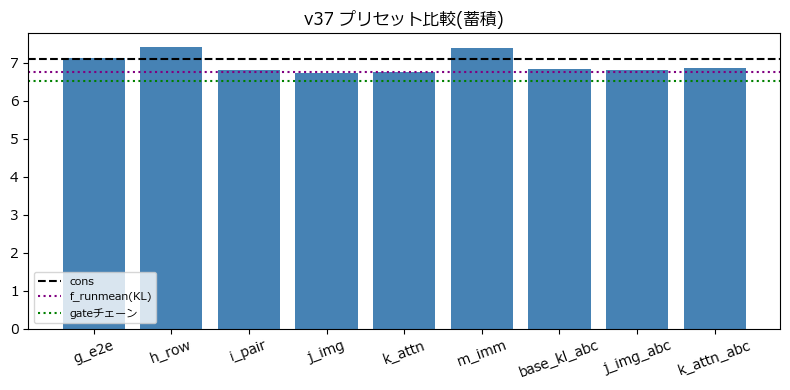

In [17]:
# ===== 評価 → results蓄積 =====
IS_EST = CFG["kind"] in ("e2e", "hyb", "row", "imm")
if IS_EST:
    e_all = [OUT_[w][0] - TRUE[w] for w in RM]
    best_ov = rmse(np.concatenate(e_all)); best_nm = "model集約(自前)"
    grid = {best_nm: best_ov}
else:
    QZ = {}
    for w in RM:
        q = OUT_[w][1].astype(np.float64); QZ[w] = (q - q.mean()) / (q.std() + 1e-9)
    def agg_overall(mode, p, wells=None):
        e_all = []
        for w in (wells or RM):
            q = QZ[w]
            if mode == "softmax":
                wgt = np.exp(-p * q); wgt = wgt / wgt.sum()
            else:
                kk = min(p, len(q)); idx = np.argsort(q)[:kk]
                wgt = np.zeros(len(q)); wgt[idx] = 1.0 / kk
            est = (wgt[:, None] * np.nan_to_num(RM[w]["TR"]).astype(np.float64)).sum(0)
            e_all.append(est - TRUE[w])
        return rmse(np.concatenate(e_all))
    res = [(f"softmax β{b}", "softmax", b) for b in (0.5, 1.0, 1.5, 2.0)] + \
          [(f"top-{n}", "topn", n) for n in (2, 4, 8)]
    grid = {nm: agg_overall(mo, pa) for nm, mo, pa in res}
    best_nm = min(grid, key=grid.get); best_ov = grid[best_nm]

# fold別(best則) + 井戸別勝率
def est_final(w):
    if IS_EST: return OUT_[w][0].astype(np.float64)
    q = QZ[w]
    if best_nm.startswith("softmax"):
        b = float(best_nm.split("β")[1]); wgt = np.exp(-b * q); wgt = wgt / wgt.sum()
    else:
        n = int(best_nm.split("-")[1]); idx = np.argsort(q)[:min(n, len(q))]
        wgt = np.zeros(len(q)); wgt[idx] = 1.0 / len(idx)
    return (wgt[:, None] * np.nan_to_num(RM[w]["TR"]).astype(np.float64)).sum(0)
per_fold = [rmse(np.concatenate([est_final(w) - TRUE[w] for w in RM if FOLD.get(w) == f])) for f in range(5)]
win = sum(1 for w in RM if rmse(est_final(w) - TRUE[w]) < rmse(RM[w]["cons"].astype(np.float64) - TRUE[w]))
rec = 100 * (cons_ov - best_ov) / max(cons_ov - or1_ov, 1e-9)
RKEY = RUN + "_abc"     # 特徴v2(A/B/C入り)の結果キー(旧結果と区別)
print(f"[{RKEY}] " + " | ".join(f"{k}:{v:.4f}" for k, v in grid.items()))
print(f"best {best_nm} = {best_ov:.4f}(cons {cons_ov:.4f} / f_runmean 6.7485 / oracle {or1_ov:.4f} → 回収 {rec:.1f}%)")
print(f"勝率 {win}/{len(RM)} | fold別 {['%.3f' % v for v in per_fold]}")
RES_FP = ART / "ranker_v37_results.json"
allres = json.loads(RES_FP.read_text()) if RES_FP.exists() else {}
allres[RKEY] = dict(best_rule=best_nm, overall=best_ov, recovery_pct=rec, win=win,
                    fold_overall=per_fold, grid=grid)
RES_FP.write_text(json.dumps(allres, indent=1))
fig, ax = plt.subplots(figsize=(8, 4))
names = list(allres.keys()); vals = [allres[k]["overall"] for k in names]
ax.bar(names, vals, color="steelblue")
ax.axhline(cons_ov, c="k", ls="--", label="cons")
ax.axhline(6.7485, c="purple", ls=":", label="f_runmean(KL)")
ax.axhline(6.5288, c="g", ls=":", label="gateチェーン")
ax.legend(fontsize=8); plt.xticks(rotation=20); ax.set_title("v37 プリセット比較(蓄積)")
plt.tight_layout(); plt.show()
